# Homework07

Exercises to practice pandas, data analysis and regression

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different regression models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!curl -L "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0   0     0   0     0     0     0  --:--:--  0:00:08 --:--:--     0
100  7183 100  7183   0     0   733     0   0:00:09  0:00:09 --:--:-- 26025
curl: (6) Could not resolve host: data_utils.py


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor

from data_utils import object_from_json_url
from data_utils import regression_error

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/DM-GY-9103-2024F-H/WK02).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [34]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

#### Nested data

This is that *nested* dataset from Week 02.

# 🤔

Let's load it into a `DataFrame` to see what happens.

In [35]:
# Read into DataFrame
ansur_df = pd.DataFrame.from_records(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear,foot,hand,head
0,18,F,66,135,1699,1645,"{'breadth': 30, 'length': 61, 'protrusion': 20}","{'breadth': 97, 'length': 243}","{'breadth': 78, 'length': 182, 'palm': 108}","{'height': 243, 'circumference': 557}"
1,30,M,68,207,1749,1715,"{'breadth': 35, 'length': 63, 'protrusion': 17}","{'breadth': 100, 'length': 252}","{'breadth': 87, 'length': 184, 'palm': 114}","{'height': 238, 'circumference': 560}"
2,27,M,67,121,1684,1657,"{'breadth': 36, 'length': 59, 'protrusion': 24}","{'breadth': 92, 'length': 251}","{'breadth': 84, 'length': 180, 'palm': 103}","{'height': 239, 'circumference': 516}"
3,20,M,73,185,1878,1828,"{'breadth': 36, 'length': 60, 'protrusion': 21}","{'breadth': 104, 'length': 280}","{'breadth': 95, 'length': 201, 'palm': 124}","{'height': 270, 'circumference': 582}"
4,33,M,76,150,1977,1883,"{'breadth': 39, 'length': 65, 'protrusion': 27}","{'breadth': 101, 'length': 271}","{'breadth': 90, 'length': 194, 'palm': 113}","{'height': 254, 'circumference': 559}"



# 😓🙄

That didn't work too well. We ended up with objects in our columns.

Luckily, our `DataFrame` library has a function called [`json_normalize()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.json_normalize.html) that can help.

In [36]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


Much better. `DataFrames` are magic.

#### Data Exploration

Before we start creating models, let's do a little bit of data analysis and get a feeling for the shapes, distributions and relationships of our data.

1. Print `min`, `max` and `average` values for all of the features.
2. Print `covariance` tables for `age`, `ear.length` and `head.circumference`.
3. Plot `age`, `ear.length` and `head.circumference` versus the $1$ *feature* that is most correlated to each of them.

Don't forget to *encode* and *normalize* the data.

In [37]:
# Work on Data Exploration here

### Encode non-numerical features
gender_order = ['M', 'F']
ansur_encoder = OrdinalEncoder(categories=[gender_order])

gender_vals = ansur_encoder.fit_transform(ansur_df[["gender"]].values)
ansur_df[["gender"]] = gender_vals

## 1. Print min, max, avg
for f in ansur_df.columns:
  print(f)
  print("\tmin:", ansur_df[f].min())
  print("\tmax:", ansur_df[f].max())
  print("\tavg:", ansur_df[f].mean())

### Normalize all data
ansur_scaler = StandardScaler().set_output(transform="pandas")
ansur_scaled_df = ansur_scaler.fit_transform(ansur_df)

## 2. Print Covariances
display(ansur_scaled_df.cov()["age"])
display(ansur_scaled_df.cov()["ear.length"])
display(ansur_scaled_df.cov()["head.circumference"])


age
	min: 17
	max: 58
	avg: 29.74535714285714
gender
	min: 0.0
	max: 1.0
	avg: 0.3273214285714286
height
	min: 56
	max: 94
	avg: 68.24732142857142
weight
	min: 0
	max: 321
	avg: 174.55839285714285
span
	min: 1323
	max: 2121
	avg: 1763.703392857143
stature
	min: 1409
	max: 1993
	avg: 1714.265357142857
ear.breadth
	min: 25
	max: 46
	avg: 35.128928571428574
ear.length
	min: 46
	max: 81
	avg: 62.637142857142855
ear.protrusion
	min: 13
	max: 34
	avg: 22.266785714285714
foot.breadth
	min: 77
	max: 126
	avg: 98.85089285714285
foot.length
	min: 198
	max: 323
	avg: 262.9919642857143
hand.breadth
	min: 67
	max: 105
	avg: 84.93696428571428
hand.length
	min: 145
	max: 239
	avg: 189.26017857142858
hand.palm
	min: 88
	max: 140
	avg: 113.91964285714286
head.height
	min: 206
	max: 295
	avg: 249.17089285714286
head.circumference
	min: 502
	max: 635
	avg: 570.0628571428572


age                   1.000179
gender               -0.062201
height                0.029467
weight                0.217017
span                  0.064304
stature               0.037972
ear.breadth           0.187740
ear.length            0.292098
ear.protrusion       -0.009254
foot.breadth          0.064993
foot.length           0.048699
hand.breadth          0.133830
hand.length           0.104642
hand.palm             0.120726
head.height           0.038637
head.circumference    0.014044
Name: age, dtype: float64

age                   0.292098
gender               -0.463540
height                0.421910
weight                0.487481
span                  0.401564
stature               0.438604
ear.breadth           0.454968
ear.length            1.000179
ear.protrusion        0.382646
foot.breadth          0.436241
foot.length           0.419030
hand.breadth          0.465829
hand.length           0.335176
hand.palm             0.341726
head.height           0.384718
head.circumference    0.283878
Name: ear.length, dtype: float64

age                   0.014044
gender               -0.339537
height                0.439234
weight                0.540160
span                  0.476903
stature               0.462999
ear.breadth           0.221058
ear.length            0.283878
ear.protrusion        0.124790
foot.breadth          0.492590
foot.length           0.501324
hand.breadth          0.466310
hand.length           0.464342
hand.palm             0.451345
head.height           0.546534
head.circumference    1.000179
Name: head.circumference, dtype: float64

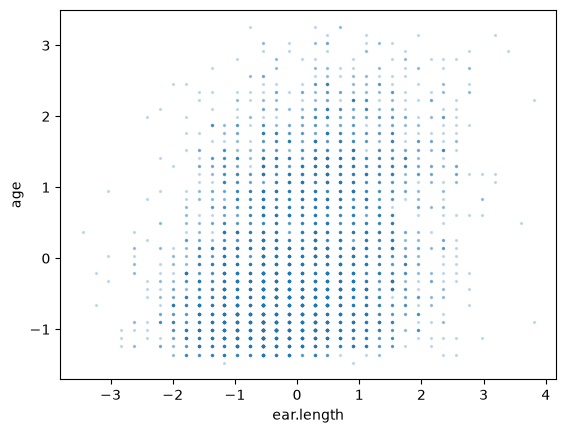

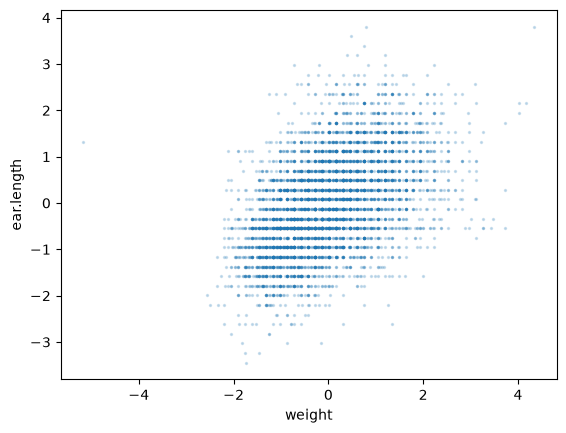

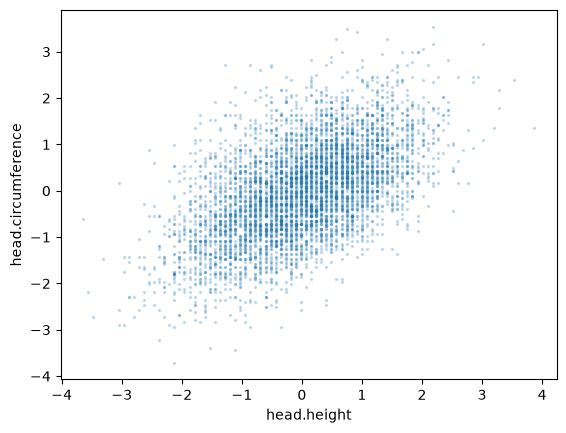

In [38]:
## 3. Plot features most correlated to age, ear length and head circumference

plt.scatter(ansur_scaled_df["ear.length"], ansur_scaled_df["age"], s=2, alpha=0.2)
plt.xlabel("ear.length")
plt.ylabel("age")
plt.show()

plt.scatter(ansur_scaled_df["weight"], ansur_scaled_df["ear.length"], s=2, alpha=0.2)
plt.xlabel("weight")
plt.ylabel("ear.length")
plt.show()

plt.scatter(ansur_scaled_df["head.height"], ansur_scaled_df["head.circumference"], s=2, alpha=0.2)
plt.xlabel("head.height")
plt.ylabel("head.circumference")
plt.show()

### Interpretation

<span style="color:hotpink;">
Does anything stand out about these graphs? Or the correlations?<br>
Are correlations symmetric? Does the feature most correlated to ear length also have ear length as its most correlated pair?
</span>

<span style="color:hotpink;">Yes, there are certain things that stand out about these graphs. First, the plot for age vs ear length looks like a more uniform cloud of points, which makes it hard to see if there is any trend. Then for the other two plots, the trends are able to be better seen as more positively correlated. Also, I believe that the correlations are symmetric in their value, but it does not necessarily mean that the one they are most correlated to will be the same. This is seen with the ear length example, as its most correlated feature was weight, but weight did not have ear length as its most correlated pair. Their values with one another were the same though. </span>

In [39]:
# Did this to check what weight was most correlated with
display(ansur_scaled_df.cov()["weight"])

age                   0.217017
gender               -0.562369
height                0.659590
weight                1.000179
span                  0.662828
stature               0.682587
ear.breadth           0.361981
ear.length            0.487481
ear.protrusion        0.242281
foot.breadth          0.708759
foot.length           0.688228
hand.breadth          0.710663
hand.length           0.599894
hand.palm             0.591608
head.height           0.521809
head.circumference    0.540160
Name: weight, dtype: float64

### Regression

Now, we want to create a regression model to predict `head.circumference` from the data.

From our [Week 07](https://github.com/PSAM-5020-2026F-A/WK07) notebook, we can create a regression model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (done! ⚡️)
3. Normalize the data (done! 🍾)
4. Separate the outcome variable and the input features
5. Create a regression model using all features
6. Run model on training data and measure error
7. Plot predictions and interpret results
8. Run model on test data, measure error, plot predictions, interpret results

In [44]:
# Work on Regression Model here

## Separate outcome variable and input features
out = ansur_scaled_df[["head.circumference"]]
ind = ansur_scaled_df.drop(columns=["head.circumference"])

## Create a regression model
model = LinearRegression().fit(ind, out)

## Run model on training data
predicted_hc = model.predict(ind)

## Measure error on training data
print(regression_error(out, predicted_hc))


0.7584338370549019


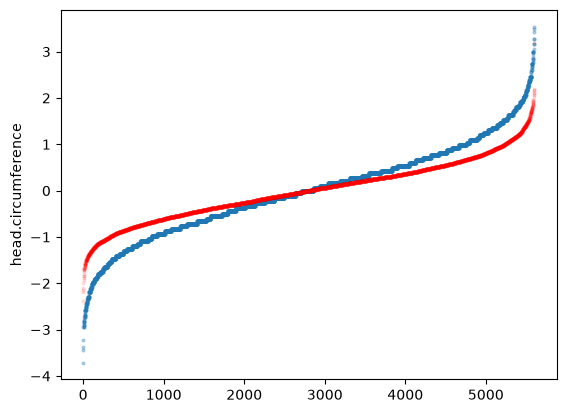

In [45]:
## Plot predictions and interpret results
plt.plot(sorted(ansur_scaled_df["head.circumference"]), marker='o', linestyle='', alpha=0.3, markersize=2)
plt.plot(sorted(predicted_hc), color='r', marker='o', markersize=2, linestyle='', alpha=0.1)
plt.ylabel("head.circumference")
plt.show()

In [46]:
## Load Test Data
ANSUR_TEST_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur-test.json"

ansur_test_data = object_from_json_url(ANSUR_TEST_FILE)
ansur_test_df = pd.json_normalize(ansur_test_data)

ansur_test_encoded_df = ansur_test_df.copy()

g_vals = ansur_encoder.transform(ansur_test_df[["gender"]])
ansur_test_encoded_df[["gender"]] = g_vals

ansur_test_scaled_df = ansur_scaler.transform(ansur_test_encoded_df)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but OrdinalEncoder was fitted without feature names
  warnings.warn(


0.7891115826821988


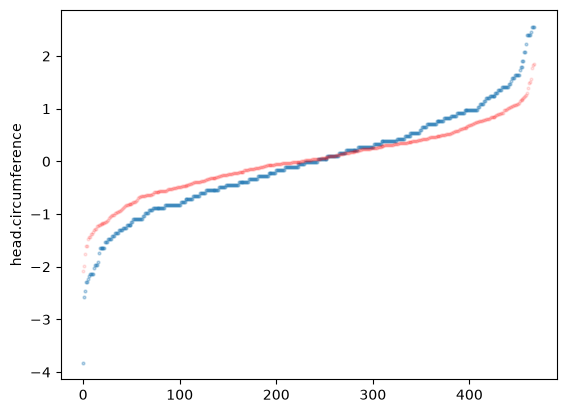

In [47]:
## Run model on test data
out_test = ansur_test_scaled_df[["head.circumference"]]
ind_test = ansur_test_scaled_df.drop(columns=["head.circumference"])

## Measure error on test data
predicted_test_hc = model.predict(ind_test)
print(regression_error(out_test, predicted_test_hc))

## Plot predictions and interpret results
plt.plot(sorted(out_test["head.circumference"]), marker='o', linestyle='', alpha=0.3, markersize=2)
plt.plot(sorted(predicted_test_hc), color='r', marker='o', markersize=2, linestyle='', alpha=0.1)
plt.ylabel("head.circumference")
plt.show()


### Interpretation

<span style="color:hotpink;">
How well does your model perform?<br>
How could you improve it?<br>
Are there ranges of circumferences that don't get predicted well?
</span>

<span style="color:hotpink;">The model performs quite consistently between the training and test data (0.758 vs 0.789). It could definitely be improved by maybe incorporating the polynomial features that we used in class to better capture the non-linear relationships. Also, it seems to struggle most with predicting the extreme ends, probably due to there being less data for smaller and larger head circumferences. </span>